<a href="https://colab.research.google.com/github/sanyasana1/MN/blob/main/%D0%9B%D0%A05_%D0%9B%D0%B0%D0%B7%D0%B0%D1%80%D0%B5%D0%BD%D0%BA%D0%BE_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
import os
import sys
import warnings
import subprocess
import importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", None)

if importlib.util.find_spec("prophet") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "prophet"])
from prophet import Prophet

if importlib.util.find_spec("tensorflow") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tensorflow"])
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

np.random.seed(42)
tf.random.set_seed(42)


In [2]:
csv_path = None
try:
    if importlib.util.find_spec("kagglehub") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub
    dataset_dir = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")
    candidates = [os.path.join(root, f) for root, _, files in os.walk(dataset_dir)
                  for f in files if f.lower().endswith(".csv")]
    preferred = [p for p in candidates if "kaggel_weather_2013_to_2024" in os.path.basename(p).lower()]
    if not candidates:
        raise FileNotFoundError("У завантаженому наборі не знайдено CSV-файлів.")
    csv_path = preferred[0] if preferred else candidates[0]
    print("Датасет завантажено:", csv_path)
except Exception as e:
    print("Автоматичне завантаження не вдалося", e)


Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Датасет завантажено: /kaggle/input/daily-climate-time-series-data-delhi-india/kaggel_weather_2013_to_2024.csv


In [3]:
if csv_path is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_path = next((name for name in uploaded if name.lower().endswith(".csv")), None)
    except ImportError:
        csv_path = input("Введіть шлях до CSV-файлу датасету: ").strip()

if not csv_path or not os.path.exists(csv_path):
    raise FileNotFoundError("CSV-файл не знайдено. Перевірте csv_path або завантажте датасет.")

df = pd.read_csv(csv_path)
display(df.head())
print("\nІнформація про датасет:")
df.info()
print("\nОписова статистика:")
display(df.describe(include="all"))


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,windspeed,sealevelpressure,conditions,Year,month,dayofweek,dayofyear,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,22.3,1008.3,"Rain, Partially cloudy",2013,4,6,104,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,17.6,1005.1,Clear,2013,4,0,105,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,27.7,1001.7,Partially cloudy,2013,4,1,106,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,22.3,1002.5,Clear,2013,4,2,107,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,12.4,1003.4,Clear,2013,4,3,108,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038



Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,windspeed,sealevelpressure,conditions,Year,month,dayofweek,dayofyear,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
unique,NaN,3556,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,5/1/2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Partially cloudy,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1382,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,1778.000000,NaN,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,1.783095,16.388249,1008.629238,NaN,2019.269328,6.542592,2.997189,185.459657,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,NaN,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,4.009455,7.093090,7.005187,NaN,3.219299,3.410053,2.001544,104.341884,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,NaN,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,0.000000,5.400000,991.700000,NaN,2013.000000,1.000000,0.000000,1.000000,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,NaN,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,0.000000,12.300000,1002.500000,NaN,2017.000000,4.000000,1.000000,97.000000,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,NaN,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,0.000000,15.400000,1008.500000,NaN,2020.000000,7.000000,3.000000,185.000000,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,NaN,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,0.000000,18.400000,1014.900000,NaN,2022.000000,10.000000,5.000000,274.000000,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622


Підготовка даних

In [10]:
df.columns = df.columns.astype(str).str.strip().str.lower()

df = df.loc[:, ~df.columns.str.contains(r"^unnamed")]

if "date" in df.columns:
    date_col = "date"
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")

elif all(col in df.columns for col in ["year", "dayofyear"]):
    df["date"] = (
        pd.to_datetime(df["year"].astype(int).astype(str), format="%Y")
        + pd.to_timedelta(
            pd.to_numeric(df["dayofyear"], errors="coerce") - 1,
            unit="D"
        )
    )
    date_col = "date"

else:
    raise ValueError(
        f"Не вдалося сформувати дату. Колонки: {list(df.columns)}"
    )


if "temp" in df.columns:
    temp_col = "temp"
elif "temperature" in df.columns:
    temp_col = "temperature"
elif "tempmean" in df.columns:
    temp_col = "tempmean"
elif "mean_temp" in df.columns:
    temp_col = "mean_temp"
else:
    numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
    candidates = [
        col for col in numeric_cols
        if "temp" in col or "temperature" in col
    ]
    if not candidates:
        raise ValueError("Не знайдено стовпець температури.")
    temp_col = candidates[0]

df = df.dropna(subset=[date_col]).copy()
df[temp_col] = pd.to_numeric(df[temp_col], errors="coerce")
df = df.dropna(subset=[temp_col])
df = df.drop_duplicates(subset=[date_col])
df = df.sort_values(date_col).set_index(date_col)

df = df.asfreq("D")
df[temp_col] = df[temp_col].interpolate(method="time").ffill().bfill()
df.index.name = "DATE"

print("Стовпець температури:", temp_col)
print("Кількість записів:", len(df))
print("Період:", df.index.min(), "-", df.index.max())

display(df.head())


Стовпець температури: temp
Кількість записів: 4249
Період: 2013-04-14 00:00:00 - 2024-11-30 00:00:00


,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,windspeed,sealevelpressure,conditions,year,month,dayofweek,dayofyear,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100.0,4.17,22.3,1008.3,"Rain, Partially cloudy",2013.0,4.0,6.0,104.0,13.0,15.0,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0.0,0.00,17.6,1005.1,Clear,2013.0,4.0,0.0,105.0,13.0,16.0,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0.0,0.00,27.7,1001.7,Partially cloudy,2013.0,4.0,1.0,106.0,13.0,16.0,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0.0,0.00,22.3,1002.5,Clear,2013.0,4.0,2.0,107.0,13.0,16.0,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0.0,0.00,12.4,1003.4,Clear,2013.0,4.0,3.0,108.0,13.0,16.0,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [11]:
print("Розмір датасету:", df.shape)
print("\nТипи даних та пропуски:")
df.info()
display(df.describe())


Розмір датасету: (4249, 27)

Типи даних та пропуски:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4249 entries, 2013-04-14 to 2024-11-30
Freq: D
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3556 non-null   float64
 1   tempmin                3556 non-null   float64
 2   temp                   4249 non-null   float64
 3   feelslikemax           3556 non-null   float64
 4   feelslikemin           3556 non-null   float64
 5   feelslike              3556 non-null   float64
 6   humidity               3556 non-null   float64
 7   precip                 3556 non-null   float64
 8   precipprob             3556 non-null   float64
 9   precipcover            3556 non-null   float64
 10  windspeed              3556 non-null   float64
 11  sealevelpressure       3556 non-null   float64
 12  conditions             3556 non-null   object 
 13  year                   3556 n

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,windspeed,sealevelpressure,year,month,dayofweek,dayofyear,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3556.000000,3556.000000,4249.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000,3556.000000
mean,31.365073,20.073847,25.431466,34.277925,20.936699,27.304921,63.764258,2.459725,23.143982,1.783597,16.386586,1008.631580,2019.268560,6.543026,2.996344,185.477784,19.268560,26.868673,1919.270807,1241.006375,1554.504165,2137.916848,1300.059699,1697.056932,11.291226,195.599722
std,7.073447,7.568369,7.228744,9.652163,9.005246,9.302266,18.124170,10.637671,42.181212,4.009908,7.093394,7.004779,3.219426,3.410434,2.001192,104.350957,3.219426,14.911475,525.858317,580.762376,539.244300,839.882256,692.667235,754.684620,3.622730,55.575946
min,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,0.000000,5.400000,991.700000,2013.000000,1.000000,0.000000,1.000000,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,0.000000,12.300000,1002.500000,2017.000000,4.000000,1.000000,97.000000,17.000000,14.000000,1542.450000,759.282500,1120.135000,1534.475000,751.912500,1113.712500,8.300000,164.448043
50%,32.950000,22.000000,27.853846,35.350000,22.000000,28.400000,65.800000,0.000000,0.000000,0.000000,15.400000,1008.500000,2020.000000,7.000000,3.000000,185.000000,20.000000,27.000000,1823.440000,1078.520000,1420.300000,1845.635000,1081.015000,1423.715000,11.600000,180.579833
75%,36.000000,26.900000,31.007692,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,0.000000,18.400000,1014.900000,2022.000000,10.000000,5.000000,274.000000,22.000000,40.000000,2341.527500,1752.770000,2035.927500,2764.697500,1864.350000,2315.295000,14.100000,233.701315
max,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,45.830000,203.800000,1024.200000,2024.000000,12.000000,6.000000,366.000000,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


In [12]:
missing = df.isna().sum().sort_values(ascending=False)
display(missing.to_frame("Кількість пропусків"))
print("Загальна кількість пропущених значень:", int(df.isna().sum().sum()))


,Кількість пропусків
tempmax,693
tempmin,693
feelslikemax,693
precip,693
feelslikemin,693
feelslike,693
humidity,693
precipcover,693
precipprob,693
windspeed,693


Загальна кількість пропущених значень: 18018


Графік температури

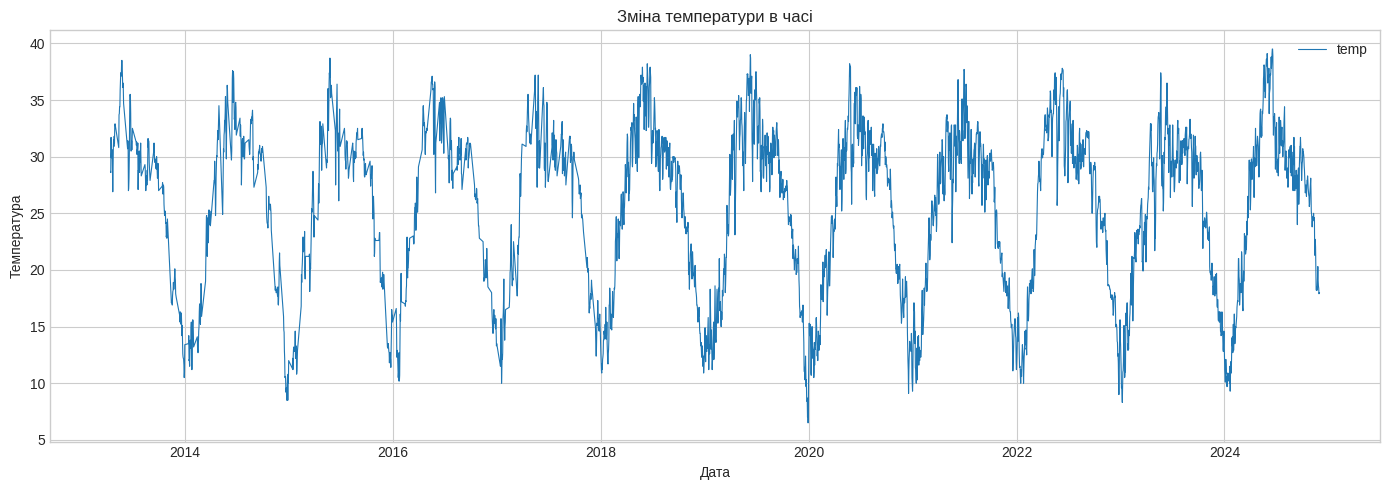

In [13]:
plt.figure(figsize=(14, 5))
plt.plot(df.index, df[temp_col], linewidth=0.8, label=temp_col)
plt.title("Зміна температури в часі")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.tight_layout()
plt.show()


Ковзне середнє

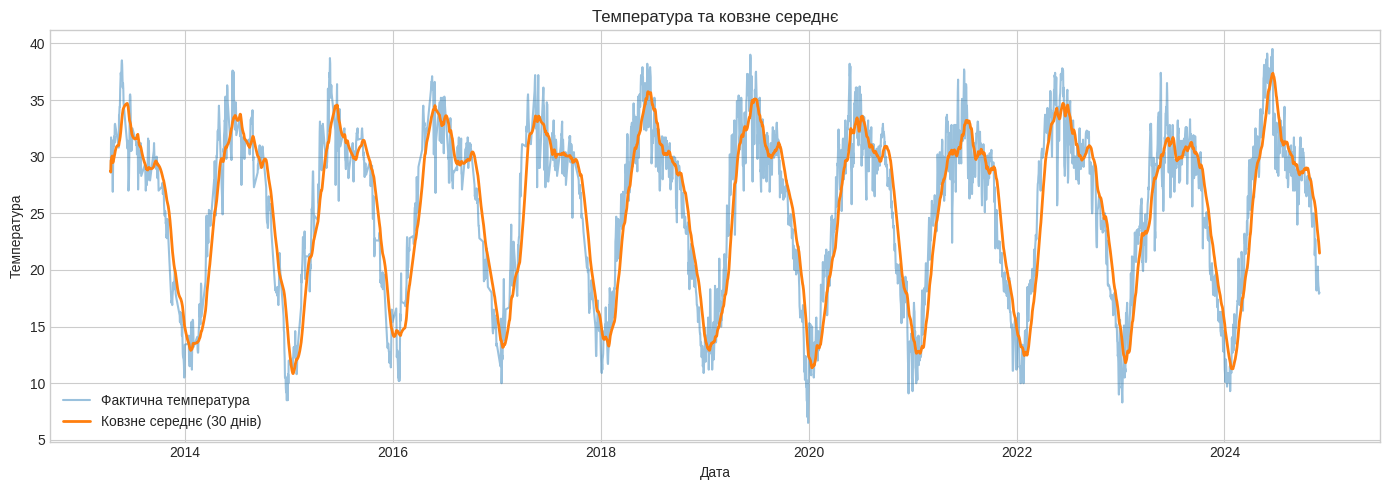

In [14]:
window = 30
df["temperature_rolling_mean"] = df[temp_col].rolling(window=window, min_periods=1).mean()
plt.figure(figsize=(14, 5))
plt.plot(df.index, df[temp_col], alpha=0.45, label="Фактична температура")
plt.plot(df.index, df["temperature_rolling_mean"], linewidth=2, label=f"Ковзне середнє ({window} днів)")
plt.title("Температура та ковзне середнє")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.tight_layout()
plt.show()


Розподіл температури

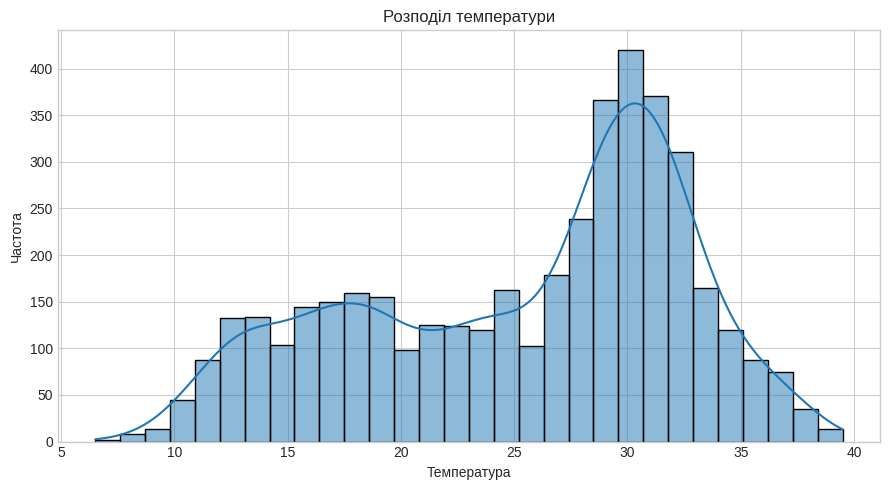

In [16]:
plt.figure(figsize=(9, 5))
sns.histplot(df[temp_col].dropna(), bins=30, kde=True)
plt.title("Розподіл температури")
plt.xlabel("Температура")
plt.ylabel("Частота")
plt.tight_layout()
plt.show()


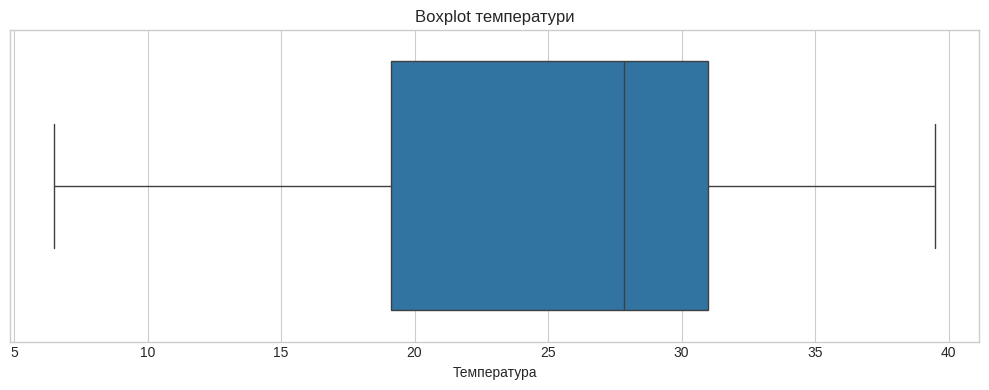

In [17]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df[temp_col])
plt.title("Boxplot температури")
plt.xlabel("Температура")
plt.tight_layout()
plt.show()
q1, q3 = df[temp_col].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[(df[temp_col] < q1 - 1.5 * iqr) | (df[temp_col] > q3 + 1.5 * iqr)]


Аналіз автокореляції
ACF

PACF

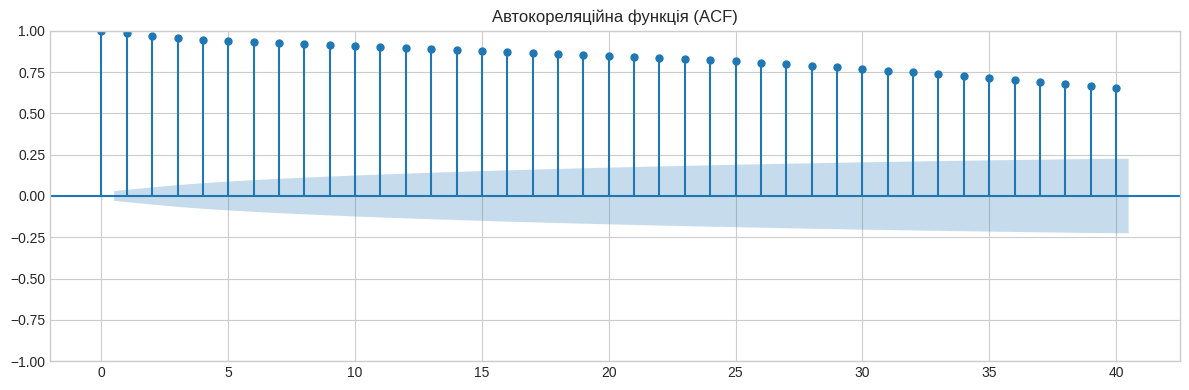

In [18]:
series = df[temp_col].dropna()
lags = min(40, max(1, len(series) // 2 - 1))
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(series, lags=lags, ax=ax)
ax.set_title("Автокореляційна функція (ACF)")
plt.tight_layout()
plt.show()


Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

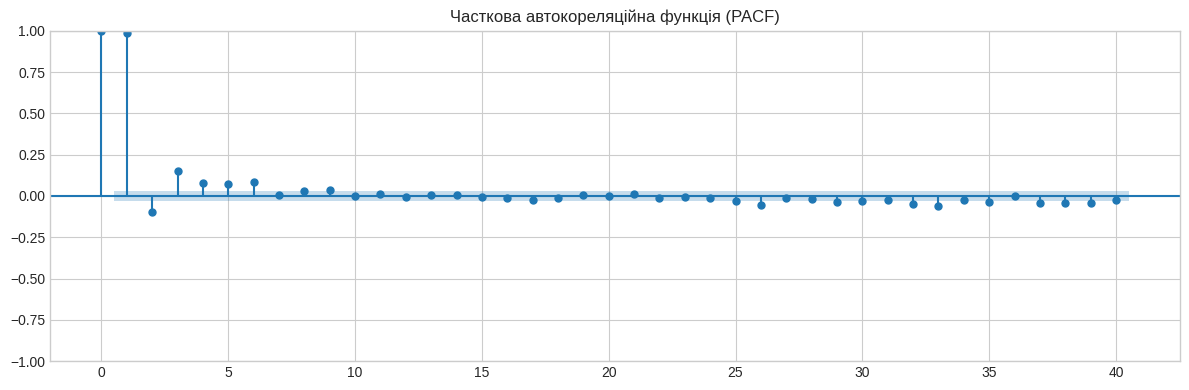

In [19]:
fig, ax = plt.subplots(figsize=(12, 4))
plot_pacf(series, lags=min(lags, max(1, len(series) // 2 - 1)), ax=ax, method="ywm")
ax.set_title("Часткова автокореляційна функція (PACF)")
plt.tight_layout()
plt.show()


Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [20]:
target = df[temp_col].astype(float).dropna()
split_idx = int(len(target) * 0.8)
train = target.iloc[:split_idx]
test = target.iloc[split_idx:]
print("Кількість train:", len(train), "| Кількість test:", len(test))
print("Train:", train.index.min(), "-", train.index.max())
print("Test:", test.index.min(), "-", test.index.max())


Кількість train: 3399 | Кількість test: 850
Train: 2013-04-14 00:00:00 - 2022-08-03 00:00:00
Test: 2022-08-04 00:00:00 - 2024-11-30 00:00:00


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [21]:
arima_model = ARIMA(train, order=(5, 1, 0))
arima_fit = arima_model.fit()
arima_forecast = arima_fit.forecast(steps=len(test))
arima_forecast = pd.Series(np.asarray(arima_forecast), index=test.index, name="ARIMA")
display(arima_forecast.head())


,ARIMA
DATE,
2022-08-04,30.403242
2022-08-05,30.193526
2022-08-06,30.096641
2022-08-07,30.057669
2022-08-08,30.133295


In [22]:
print(arima_fit.summary())


                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 3399
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -5410.812
Date:                Sat, 24 Oct 2026   AIC                          10833.624
Time:                        01:43:37   BIC                          10870.410
Sample:                    04-14-2013   HQIC                         10846.772
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0859      0.013      6.667      0.000       0.061       0.111
ar.L2         -0.1769      0.014    -12.853      0.000      -0.204      -0.150
ar.L3         -0.0955      0.016     -6.132      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

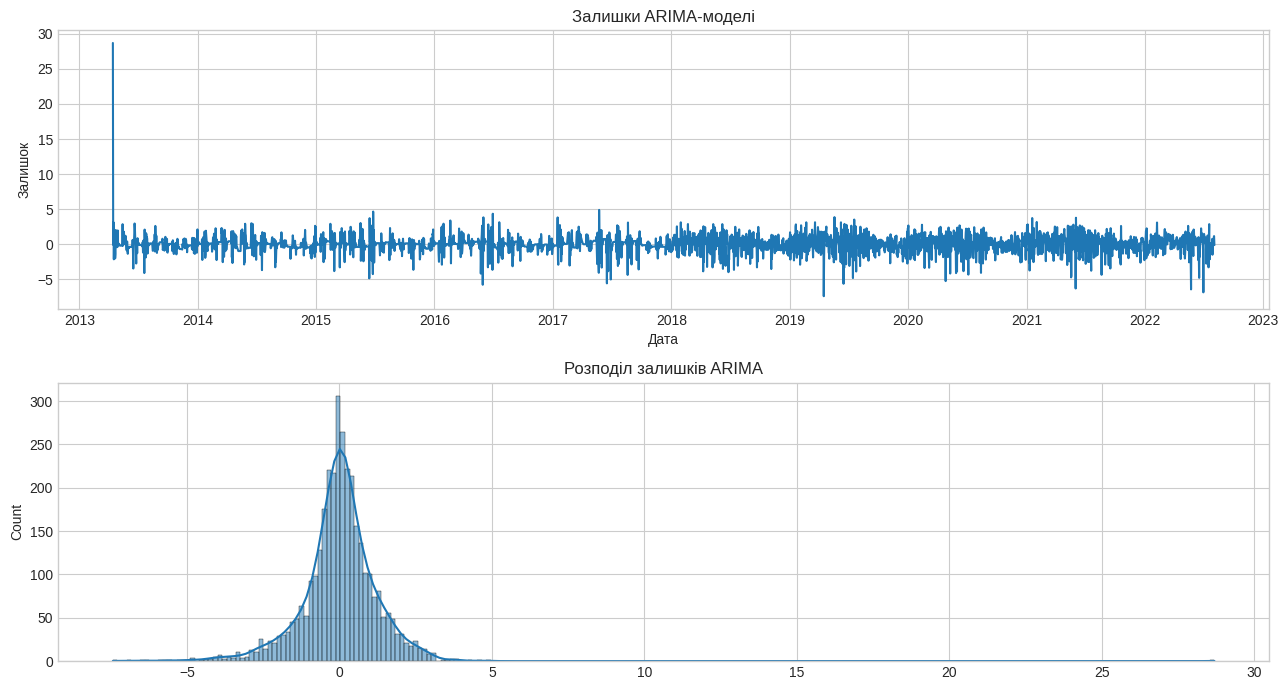

In [23]:
residuals = arima_fit.resid
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
axes[0].plot(residuals)
axes[0].set_title("Залишки ARIMA-моделі")
axes[0].set_xlabel("Дата")
axes[0].set_ylabel("Залишок")
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Розподіл залишків ARIMA")
plt.tight_layout()
plt.show()


In [24]:
def calculate_mape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.abs(y_true) > 1e-8
    if not mask.any():
        return np.nan
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": calculate_mape(y_true, y_pred)
    }

arima_metrics = calculate_metrics(test, arima_forecast)
display(pd.DataFrame([arima_metrics], index=["ARIMA"]))


,MAE,RMSE,MAPE (%)
ARIMA,6.236699,8.457075,36.039114


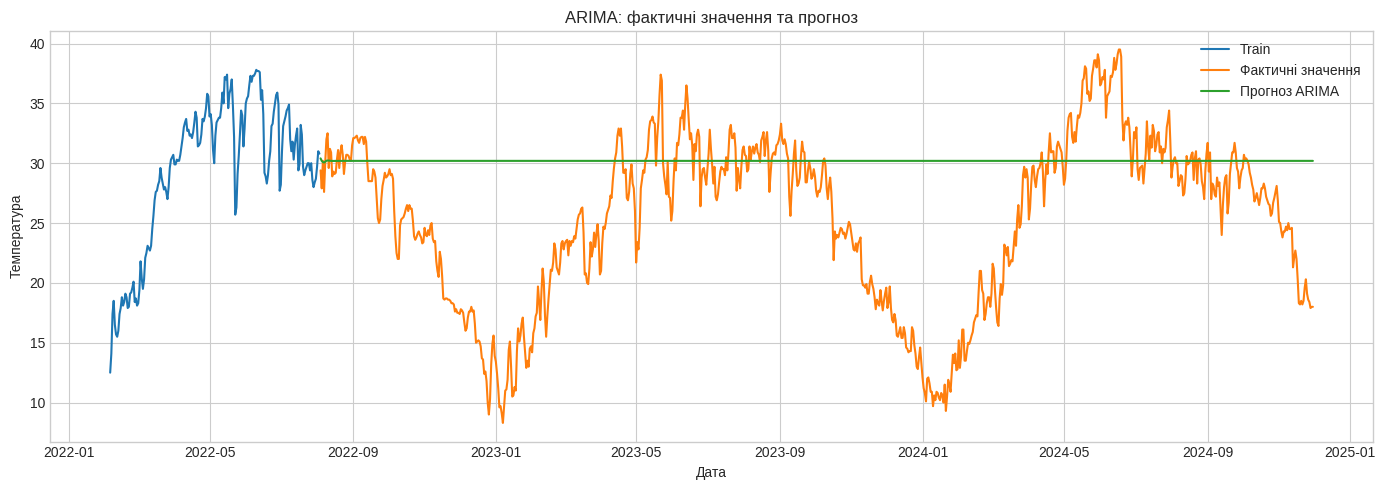

In [25]:
plt.figure(figsize=(14, 5))
plt.plot(train.index[-min(180, len(train)):], train.iloc[-min(180, len(train)):], label="Train")
plt.plot(test.index, test, label="Фактичні значення", linewidth=1.5)
plt.plot(arima_forecast.index, arima_forecast, label="Прогноз ARIMA")
plt.title("ARIMA: фактичні значення та прогноз")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.tight_layout()
plt.show()


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [26]:
prophet_train = pd.DataFrame({"ds": train.index, "y": train.values})
prophet_test = pd.DataFrame({"ds": test.index, "y": test.values})
display(prophet_train.head())


,ds,y
0,2013-04-14,28.7
1,2013-04-15,28.6
2,2013-04-16,31.7
3,2013-04-17,29.9
4,2013-04-18,30.6


In [27]:
prophet_model = Prophet(yearly_seasonality=True, weekly_seasonality=True,
                        daily_seasonality=False, seasonality_mode="additive")
prophet_model.fit(prophet_train)


Прогноз

In [28]:
future = prophet_model.make_future_dataframe(periods=len(test), freq="D", include_history=True)
prophet_all_forecast = prophet_model.predict(future)
prophet_forecast = prophet_all_forecast.set_index("ds").loc[test.index, "yhat"]
prophet_forecast.name = "Prophet"
display(prophet_forecast.head())


,Prophet
DATE,
2022-08-04,30.472997
2022-08-05,30.501332
2022-08-06,30.522214
2022-08-07,30.534157
2022-08-08,30.675759


In [29]:
prophet_metrics = calculate_metrics(test, prophet_forecast)
display(pd.DataFrame([prophet_metrics], index=["Prophet"]))


,MAE,RMSE,MAPE (%)
Prophet,2.066908,2.64553,9.342319


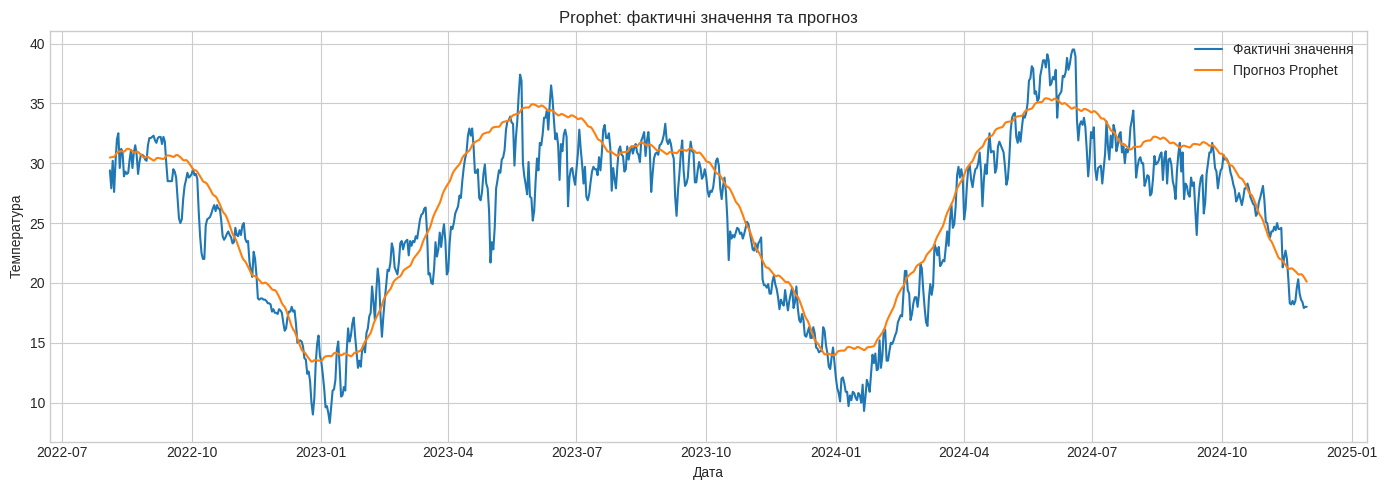

In [30]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test.index, test, label="Фактичні значення")
ax.plot(prophet_forecast.index, prophet_forecast, label="Прогноз Prophet")
ax.set_title("Prophet: фактичні значення та прогноз")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура")
ax.legend()
plt.tight_layout()
plt.show()


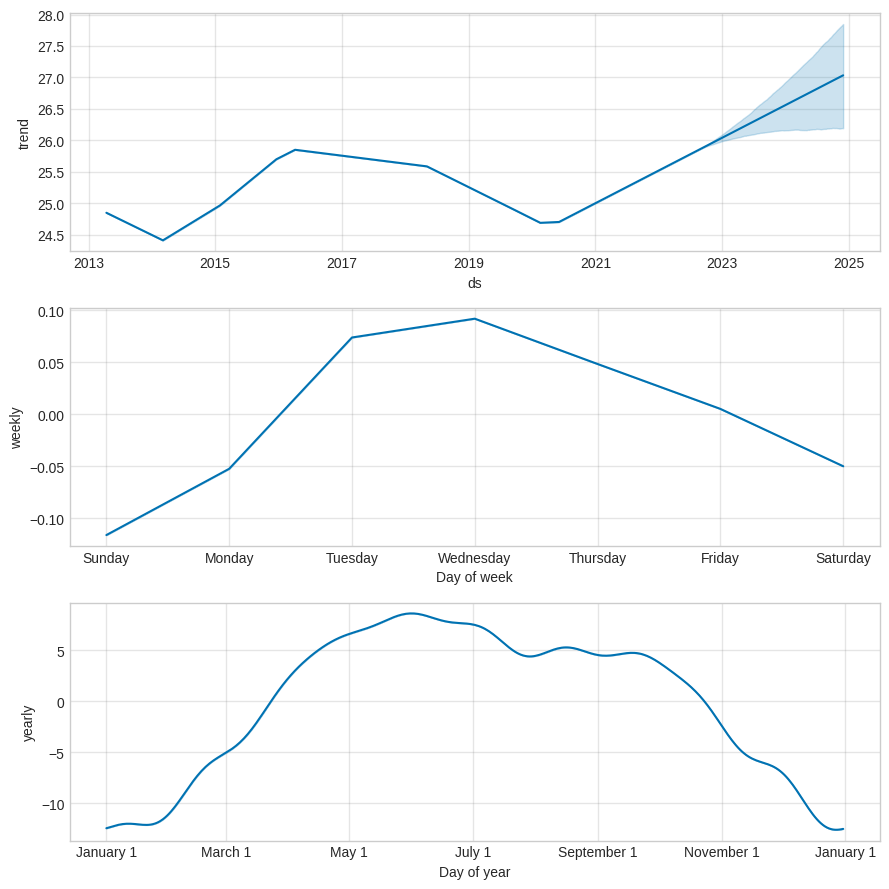

In [31]:
prophet_model.plot_components(prophet_all_forecast)
plt.tight_layout()
plt.show()


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [36]:
look_back = 30
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train.to_numpy().reshape(-1, 1))
all_scaled = scaler.transform(target.to_numpy().reshape(-1, 1))

def make_sequences(values, look_back):
    X, y = [], []
    for i in range(look_back, len(values)):
        X.append(values[i-look_back:i, 0])
        y.append(values[i, 0])
    return np.array(X), np.array(y)

X_train, y_train = make_sequences(train_scaled, look_back)
test_input = all_scaled[split_idx-look_back:]
X_test, y_test_scaled = make_sequences(test_input, look_back)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))
print("X_train:", X_train.shape, "X_test:", X_test.shape)


X_train: (3369, 30, 1) X_test: (850, 30, 1)


In [35]:
print(f"Train-послідовностей: {len(X_train)}")
print(f"Test-послідовностей: {len(X_test)}")
assert len(X_test) == len(test), "Кількість прогнозів LSTM має збігатися з тестовою вибіркою."


Train-послідовностей: 3369
Test-послідовностей: 850


In [34]:
lstm_model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(look_back, 1)),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])
lstm_model.compile(optimizer="adam", loss="mean_squared_error")
lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                                  restore_best_weights=True)
history = lstm_model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 0.0363 - val_loss: 0.0056
Epoch 2/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0112 - val_loss: 0.0050
Epoch 3/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0090 - val_loss: 0.0048
Epoch 4/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0083 - val_loss: 0.0045
Epoch 5/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0078 - val_loss: 0.0044
Epoch 6/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0068 - val_loss: 0.0043
Epoch 7/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0063 - val_loss: 0.0046
Epoch 8/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0065 - val_loss: 0.0042
Epoch 9/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0056 - val_loss: 0.0041
Epoch 10/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0056 - val_loss: 0.0041
Epoch 11/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0053 - val_loss: 0.0038
Epoch 12/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0048 - val_l

In [38]:
lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,573 (349.90 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 59,716 (233.27 KB)

In [39]:
lstm_pred_scaled = lstm_model.predict(X_test, verbose=0)
lstm_forecast_values = scaler.inverse_transform(lstm_pred_scaled).ravel()
lstm_forecast = pd.Series(lstm_forecast_values, index=test.index, name="LSTM")
display(lstm_forecast.head())


,LSTM
DATE,
2022-08-04,29.450462
2022-08-05,28.598072
2022-08-06,27.402946
2022-08-07,28.190105
2022-08-08,27.292564


In [40]:
lstm_test_dates = test.index
print("Період прогнозу LSTM:", lstm_test_dates.min(), "-", lstm_test_dates.max())
print("Кількість часових міток:", len(lstm_test_dates))


Період прогнозу LSTM: 2022-08-04 00:00:00 - 2024-11-30 00:00:00
Кількість часових міток: 850


In [41]:
lstm_metrics = calculate_metrics(test, lstm_forecast)
display(pd.DataFrame([lstm_metrics], index=["LSTM"]))


,MAE,RMSE,MAPE (%)
LSTM,1.341442,1.657811,5.618399


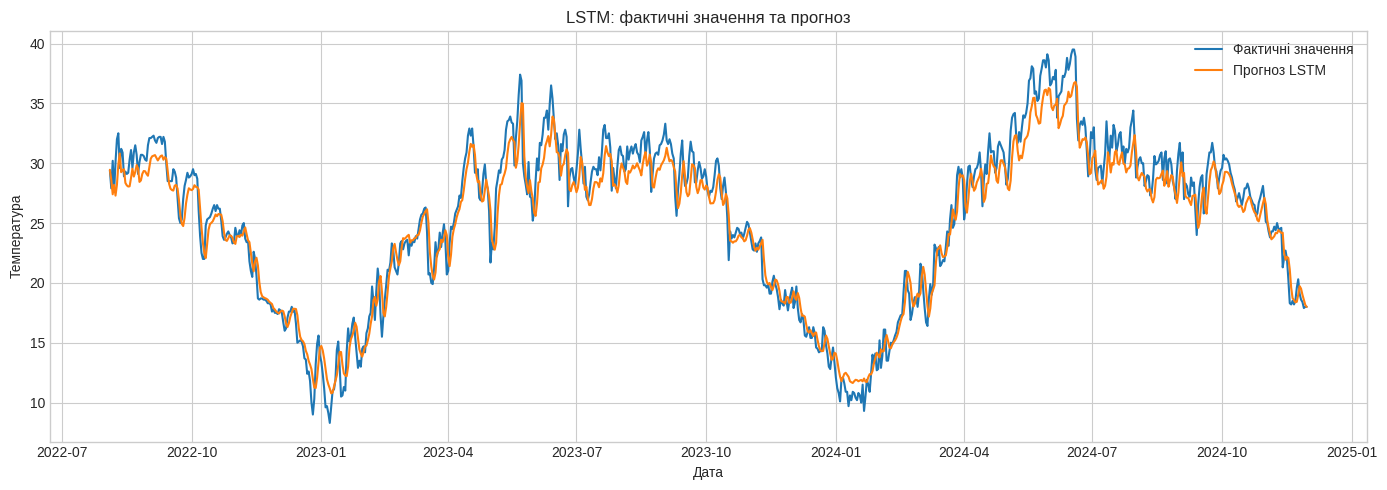

In [42]:
plt.figure(figsize=(14, 5))
plt.plot(test.index, test, label="Фактичні значення")
plt.plot(lstm_forecast.index, lstm_forecast, label="Прогноз LSTM")
plt.title("LSTM: фактичні значення та прогноз")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.tight_layout()
plt.show()


Порівняння моделей

In [43]:
comparison = pd.DataFrame(
    [arima_metrics, prophet_metrics, lstm_metrics],
    index=["ARIMA", "Prophet", "LSTM"]
).sort_values("RMSE")
display(comparison.style.format("{:.3f}"))
best_model = comparison["RMSE"].idxmin()
print(f"Найменше RMSE отримала модель: {best_model}.")


,MAE,RMSE,MAPE (%)
LSTM,1.341,1.658,5.618
Prophet,2.067,2.646,9.342
ARIMA,6.237,8.457,36.039


Найменше RMSE отримала модель: LSTM.
Порівнюйте MAE, RMSE та MAPE: менші значення означають точніший прогноз.


## Висновок

У роботі виконано дослідницький аналіз щоденних кліматичних даних: перевірено структуру та пропущені значення, побудовано графіки температури, ковзного середнього, розподілу, ACF і PACF. Для прогнозування побудовано моделі ARIMA, Prophet та LSTM, які оцінено за метриками MAE, RMSE і MAPE. Найкращу модель визначено за найменшим значенням похибок у підсумковій таблиці. LSTM виявилась найкращою.
